# GridWorld:
- calculating the expected discounted jtotal future reward from each square on a grid box. 
- replicating figure 3.2 

## Defining Grid Movement Rules


In [1]:
import numpy as np
import matplotlib.pyplot as plt

# define the environment for GridWorld
class GridWorld:
    def __init__(self):
        self.size = 5
        # each position is written as (row, column) that starts from 0

        # the special blocks that 'teleports' the agent to A' and B' 
        # coordinates are defined accordingly to the figure's position
        self.A = (0, 1)
        # teleports to row 4 and column 1
        self.A_prime = (4, 1)
        self.B = (0, 3)
        # teleports to row 2 and column 3
        self.B_prime = (2, 3)

        # define a set of actions that moves to up down left or right 
        self.action = [
            (-1, 0), # up one row
            (1, 0), # down one row
            (0, -1), # left one column
            (0, 1), # right one column 
        ]
    # function that returns the next position and immediate reward
    def step(self, state, action):
        # special states (or blocks) override the normal movement rules by 'teleporting'
        # returns the new block position and the relevant reward obtained by teleporting to that special block location
        if state == self.A:
            return self.A_prime, 10

        if state == self.B:
            return self.B_prime, 5

        # updating the row and column numbers 
        row, column = state
        row_change, column_change = action
        new_row = row + row_change
        new_column = column + column_change

        # trying to leave the grid keeps the agent in the same square
        if (new_row < 0 or new_row >= self.size or new_column < 0 or new_column >= self.size):
            # stay in the current square and receive a reward of -1 for this illegal move. 
            return state, -1
        # otherwise an ordinary move would change the position but the reward would be zero
        return (new_row, new_column), 0


### Trying the movement controls

In [ ]:
environment = GridWorld()
# at state grid 0, 0 and move upward to hit the wall, would recieve -1 reward
print(environment.step((0, 0), (-1, 0)))
# at state grid 0, 0 and move right into A (0, 1)
print(environment.step((0, 0), (0, 1)))
# at point A 
print(environment.step((0, 1), (1, 0)))

((0, 0), -1)
((0, 1), 0)
((4, 1), 10)


## Defining the transition matrix & reward vector

In [8]:
def build_grid_environment(environment):
    # defining the num of states as the square of the size
    num_states = environment.size * environment.size

    # initializing the transition matrix P 
    P = np.zeros((num_states, num_states))

    # initilizing the expected immediate reward for each state
    r = np.zeros(num_states)

    # implementing a policy of randomly choosing any of the nearby blocks with equal probability
    action_prob = 1 / len(environment.action)

    for row in range(environment.size):
        for column in range(environment.size):
            state = (row, column)

            # convert a grid position into an index from 0 to 24
            state_index = row * environment.size + column

            for action in environment.action:
                next_state, reward = environment.step(state, action)
                next_row, next_column = next_state
                next_index = next_row * environment.size + next_column

                # add this action's probability to its destination
                P[state_index, next_index] += action_prob

                # add this action's contribution to the expected reward
                r[state_index] += action_prob * reward
    return P, r

In [ ]:
# create an object containing the grid size, special squares, available actions,and movement rules
environment = GridWorld()

# extract the probabilities of moving between states and expected immediate reward from each state
P, r = build_grid_environment(environment)

# expected 25, 25 grids 
print(P.shape) 
# expected one dimensional array with 25 entries, one expected immediate reward per starting state
print(r.shape)

# print the entire row of starting state 0 of the top left square 
print(P[0])

# from state 0, the four equally likely actions give rewards:
# up: -1     Down: 0     Left: -1      Right: 0
# the probability weighted average would be -0.5
print(r[0])


(25, 25)
(25,)
[0.5  0.25 0.   0.   0.   0.25 0.   0.   0.   0.   0.   0.   0.   0.
 0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.  ]
-0.5


## Policy evaluation + reward calculation
- Now we have an environment class `GridWorld` that defines what happens when you take an action from a square, a `build_model(environment)` examines those rules and produces `P` and `r` for the random policy. 
- Here we define `evaluate_policy(P, r)` will use those arrays to alculate each square's expected discounted future reward.

In [10]:
# gamma is defined in figure 3.2 
# tolerance is just a choice here to control how many iterations of calculations should take place
def evaluate_policy(P, r, gamma=0.9, tolerance=0.000001):
    # r contains one entry per state, so its length is the state count
    num_states = len(r)

    # initially, estimate every state's future return as zero
    values = np.zeros(num_states)

    while True: 
        # for each starting state, multiply each destination's value by its transition probability, then add those contributions:
        expected_next_values = P @ values

        # apply the Bellman equation to all 25 states:
        # expected immediate reward + discounted expected next-state value
        new_values = r + gamma * expected_next_values

        # calculate how much each state's reward changed
        changes = np.abs(new_values - values)

        # check the state whose estimate changed the most
        largest_change = np.max(changes)

        # use the new estimates for the next iteration
        values = new_values

        # stop once every state's change is smaller than the tolerance
        if largest_change < tolerance:
            break
    return values


In [ ]:
# create the environment containing the movement and reward rules
environment = GridWorld()

# convert those rules into transition probabilities and expected rewards
P, r = build_grid_environment(environment)

# repeatedly apply the Bellman equation until the values stabilize
values = evaluate_policy(P, r)

# convert the 25-element array back into the grid's 5 rows and 5 columns
# values[0] goes in the top-left square, values[1] goes beside it, etc...
grid_values = values.reshape(environment.size, environment.size)
print(np.round(grid_values, 1))

[[ 3.3  8.8  4.4  5.3  1.5]
 [ 1.5  3.   2.3  1.9  0.5]
 [ 0.1  0.7  0.7  0.4 -0.4]
 [-1.  -0.4 -0.4 -0.6 -1.2]
 [-1.9 -1.3 -1.2 -1.4 -2. ]]


## Visualization

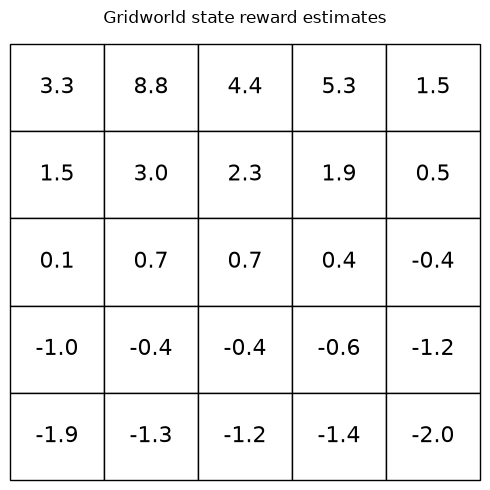

In [ ]:
# format each value as text with exactly one decimal place
table_text = []

for row in grid_values:
    row_text = []

    for value in row:
        row_text.append(f"{value:.1f}")

    table_text.append(row_text)
fig, ax = plt.subplots(figsize=(5, 5))
ax.set_axis_off()

# fill the plotting area with a table of the calculated values
table = ax.table(
    cellText=table_text,
    cellLoc="center",
    bbox=[0, 0, 1, 1]
)

table.auto_set_font_size(False)
table.set_fontsize(16)

# give every square a white background and black border
for cell in table.get_celld().values():
    cell.set_facecolor("white")
    cell.set_edgecolor("black")
    cell.set_linewidth(1)

ax.set_title("Gridworld state reward estimates", pad=15)

plt.tight_layout()
plt.show()